# Część 3 · polars-bio i vepyr: analizy ad hoc, równoległość, streaming

**Big Data w genomice · OMICS Data Science 2026 · około 120 minut**

W części 1 dzieliliśmy dane na partycje w Sparku, a w części 2 dzieliliśmy potok na zadania (shardy) w WDL. Teraz zobaczymy trzecią drogę: **jedna maszyna, wiele wątków i przetwarzanie porcjami**, z bibliotekami napisanymi w Ruście i dostępnymi z Pythona. Mamy gotowy VCF po analizie NGS. Sprawdzimy, które z milionów wariantów znajdują się w eksonach genów, zmierzymy na własnym laptopie, ile dają kolejne wątki, zapiszemy duży wynik bez zbierania całej tabeli w RAM i dodamy adnotację biologiczną narzędziem vepyr.

| Minuty | Etap |
|---|---|
| 0–10 | C0–C1: start, zasoby kontenera, dane |
| 10–30 | C2: które SNV przecinają eksony? Leniwy plan zapytania w polars-bio |
| 30–55 | C3: równoległość – pomiar na Twoim laptopie |
| 55–75 | C4: streaming i pamięć RAM |
| 75–110 | C5: adnotacja vepyrem, równoległe workery, interpretacja wyniku |
| 110–120 | C6: dane w kubełkach, wynik z części 2, podsumowanie dnia |

**VCF (Variant Call Format)** to format zapisu wariantów: każdy rekord opisuje m.in. chromosom, pozycję oraz allel referencyjny REF i alternatywny ALT. Wyniki zapisujemy w formacie **Parquet**, który poznaliśmy w części 1.

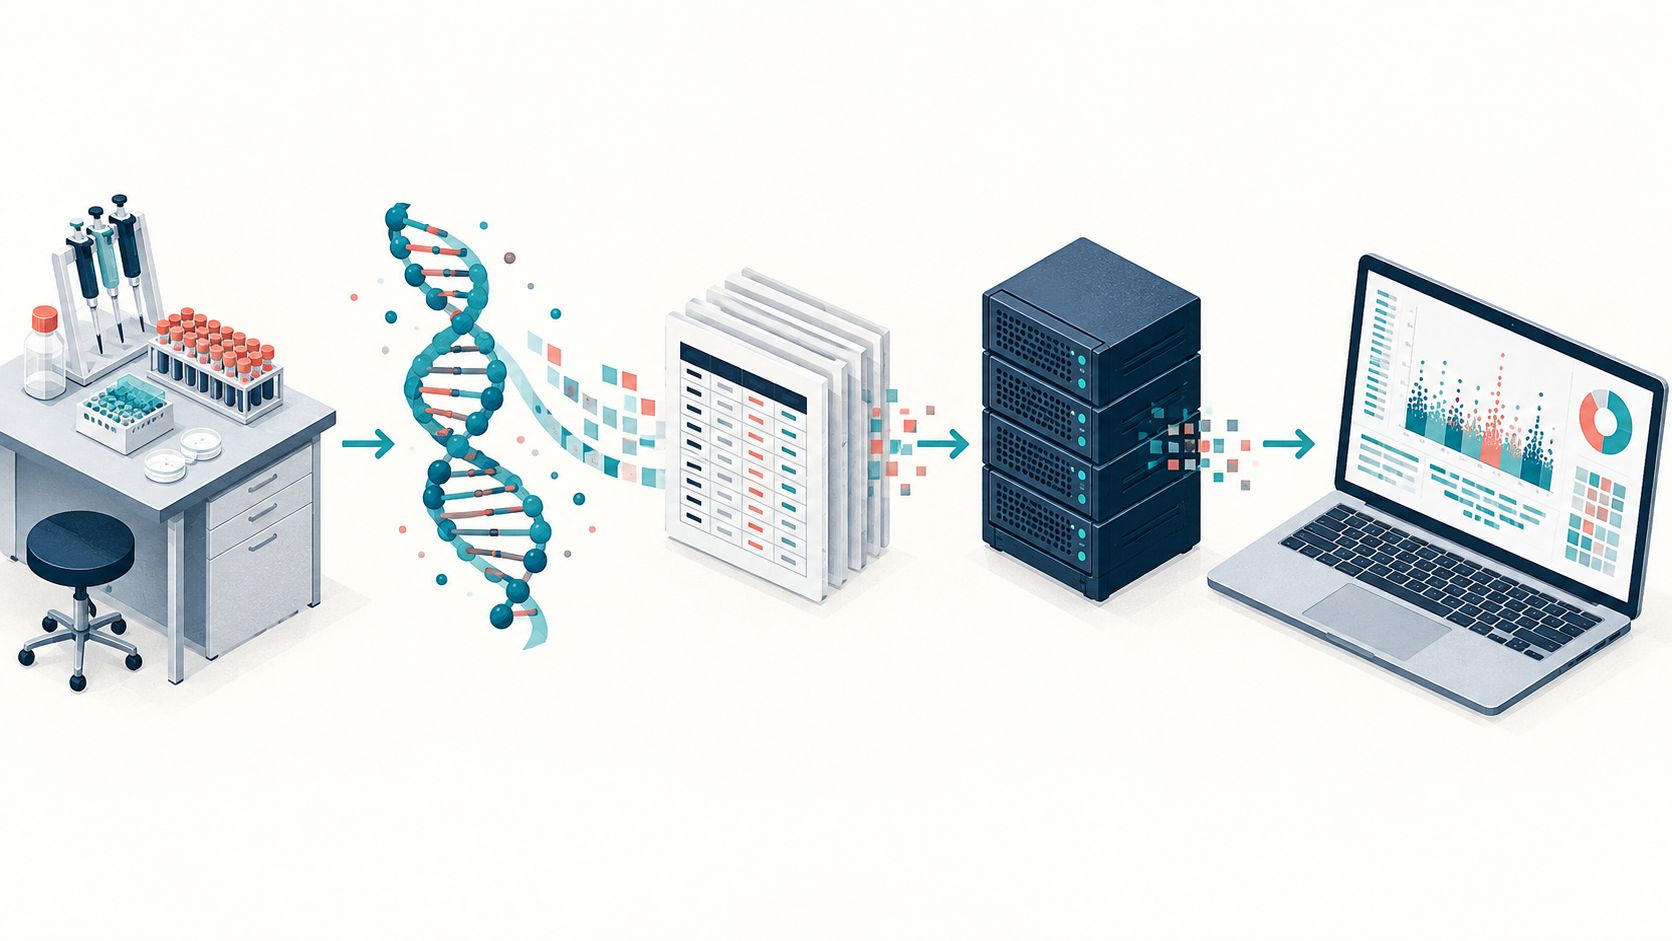

*Warianty, obliczenia i czytelny wynik. Ilustracja koncepcyjna.*

## C0 · Start

Wszystkie dane są już w obrazie Dockera. Komórka poniżej sprawdza ich sumy kontrolne i przygotowuje pliki robocze; trwa kilka–kilkanaście sekund. Wyniki zapisujemy w katalogu `wyniki/` obok notatnika.

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, '/opt/workshop/part3/scripts')
import colab_helpers as wh
import workshop_helpers as ws

ROOT = wh.ROOT
OUT = Path('wyniki')
OUT.mkdir(exist_ok=True)
vcf, annotation_vcf, cache, variants, exons, reference_fasta = wh.setup()
wh.resources()

## C1 · Gdzie są nasze dane i obliczenia?
Przeglądarka pokazuje notebook, a kod wykonuje **kontener Dockera na Twoim laptopie**. Kontener widzi tyle **CPU** i **RAM**, ile przydzielono Dockerowi (Docker Desktop → Settings → Resources). Pliki robocze leżą w wolumenie `omics-2026`, który przetrwa zamknięcie kontenera.

### Co może ograniczać analizę?

| Zasób | Rola | Co zauważysz, gdy go brakuje lub działa wolno? |
|---|---|---|
| CPU — procesor | Wykonuje obliczenia, np. rozpakowuje i filtruje dane | Długi czas obliczeń |
| RAM — pamięć operacyjna | Przechowuje tabele robocze i bufory | Cały wynik nie mieści się w pamięci |
| Dysk | Przechowuje wejścia i wyniki | Brak miejsca lub wolny odczyt i zapis |
| Sieć | Przenosi pliki między usługami | Długie pobieranie VCF lub bazy |

Więcej CPU pomaga, jeżeli narzędzie potrafi rozdzielić pracę – zmierzymy to w C3. Gdy problemem jest wielkość tabeli w RAM, pomaga przetwarzanie porcjami (C4).

### Dane
**Genome in a Bottle, HG002, v4.2.1, GRCh38.** Publiczny zestaw referencyjny; GRCh38 to wersja genomu odniesienia, względem której zapisano pozycje wariantów. Pełny VCF autosomów (chromosomy 1–22, około 156 MB po kompresji) jest źródłem wariantów do ćwiczeń. Uwaga: to **inny genom odniesienia** (GRCh38) niż w częściach 1 i 2 (b37, fragment chr20).

Do przecięć przedziałowych używamy **GENCODE 47 basic / GRCh38**: publicznej mapy genów i ich eksonów w formacie GTF (około 34 MB po kompresji). Oba źródła muszą opisywać ten sam genom odniesienia. C0 utworzyło z nich dwie tabele Parquet: **3 458 690 SNV** i **513 903 przedziały eksonów**. [GENCODE 47](https://www.gencodegenes.org/human/release_47.html).

Do adnotacji wybieramy **50 284 rekordy chr22** i cache **Ensembl 116 / GRCh38** (około 496 MB). **Cache adnotacyjny** to pobrana wcześniej baza, z której narzędzie odczytuje m.in. informacje o transkryptach i znanych wariantach. **FASTA** to tekstowy format sekwencji DNA; do adnotacji potrzebujemy sekwencji **GRCh38 chr22**. Cache dostarcza opisów biologicznych, a FASTA — sekwencji genomu.

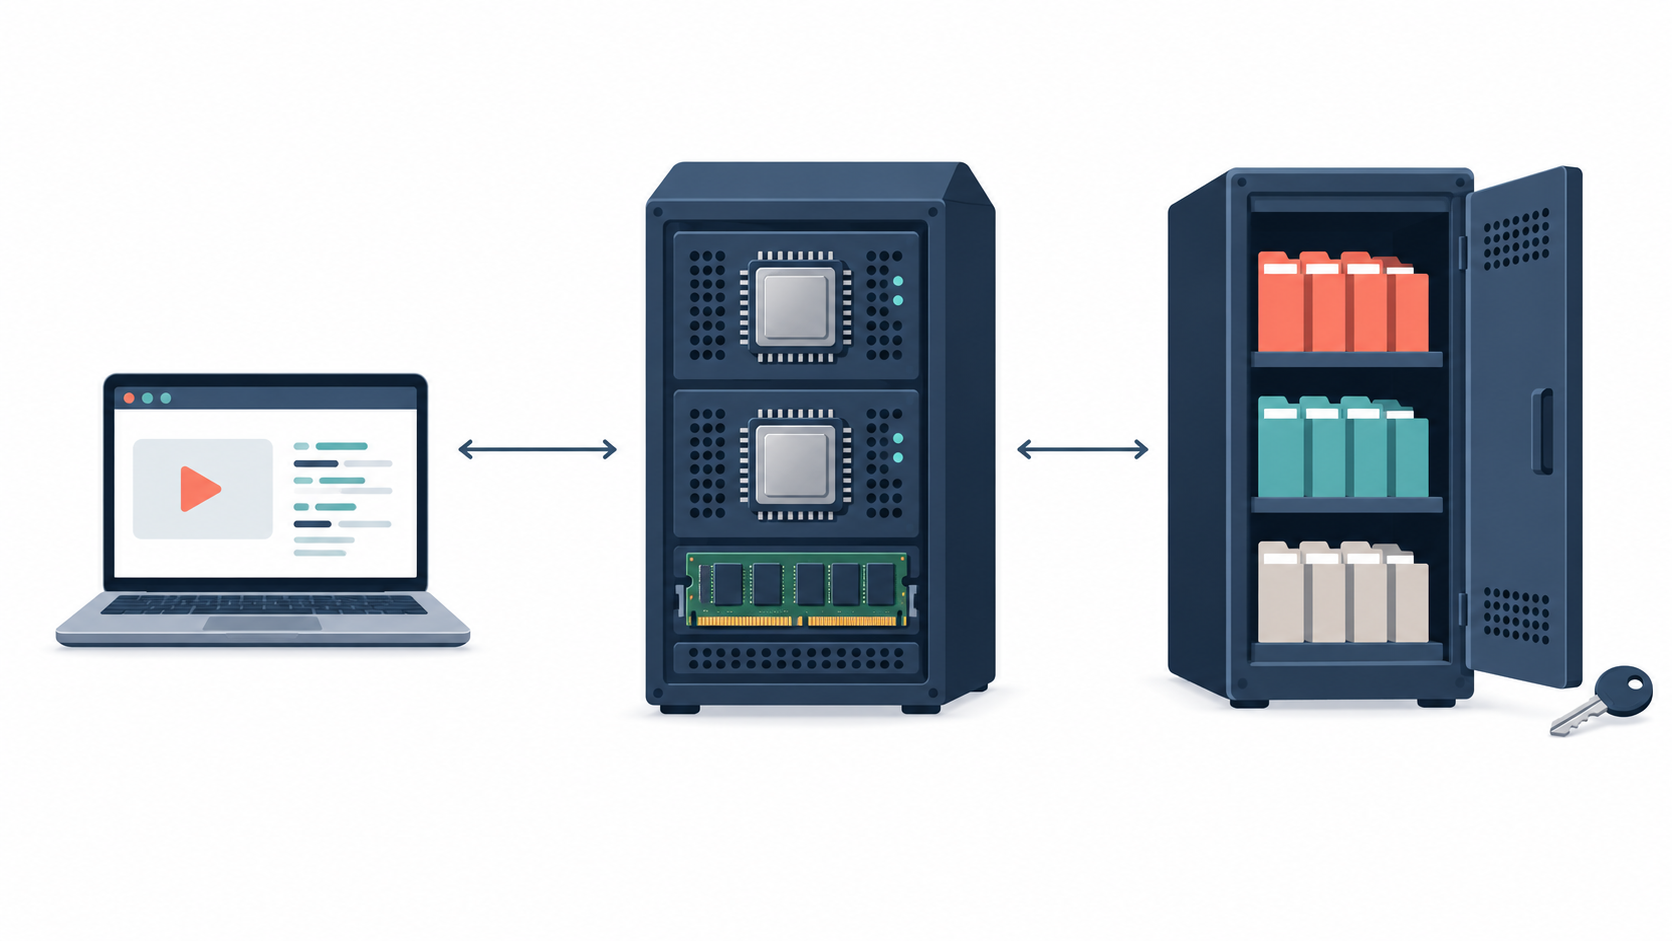

*Przeglądarka, maszyna obliczeniowa i magazyn plików. Ilustracja koncepcyjna.*

## C2 · Które warianty przecinają eksony?
**polars-bio** pozwala czytać formaty bioinformatyczne (VCF, BAM, FASTQ, GFF, BED...) i wykonywać operacje na przedziałach genomowych. Silnikiem obliczeń jest Apache DataFusion (Rust), a wyniki trafiają do ramek **Polars**. **Przecięcie przedziałów (overlap)** wyszukuje fragmenty zajmujące wspólne pozycje na tym samym chromosomie. Pytamy: **które SNV HG002 leżą w eksonach i do jakich genów je przypiszemy?** [Operacje przedziałowe polars-bio](https://biodatageeks.org/polars-bio/api/operations/).

**SNV (single nucleotide variant)** to zmiana jednego nukleotydu, np. `A → G`. C0 wybrało z VCF rekordy autosomów z jednym znakiem REF i jednym ALT. **Ekson** to fragment genu zachowywany w dojrzałym RNA; w tabeli usunęliśmy powtórzenia identycznych granic dla tego samego genu (**513 903 przedziały**).

### Najpierw uzgadniamy współrzędne
VCF i GTF numerują pozycje od 1. Do obu tabel Parquet przeliczamy je na **przedziały od 0 z wyłączonym końcem**: `[start, end)`. SNV zajmuje przedział długości 1.

| Przykład na tym samym chromosomie | Zapis wejściowy | Przedział w naszej tabeli | Przecina ekson? |
|---|---|---|---|
| Ekson | GTF: 101–105, obie granice włącznie | `[100, 105)` | — |
| SNV na początku eksonu | VCF: POS=101 | `[100, 101)` | Tak |
| SNV na końcu eksonu | VCF: POS=105 | `[104, 105)` | Tak |
| SNV tuż za eksonem | VCF: POS=106 | `[105, 106)` | Nie |

Warunek przecięcia to ten sam chromosom oraz `start_wariantu < end_eksonu` i `end_wariantu > start_eksonu`. Biblioteka wyszukuje takie pary za pomocą indeksu przedziałowego.

### Leniwe przetwarzanie – przypomnienie z części 1
Tak jak w Sparku, najpierw budujemy **plan**, a obliczenia uruchamia dopiero żądanie wyniku. W Polars **LazyFrame** to plan (odpowiednik ramki Sparka przed akcją), a **DataFrame** – gotowa tabela w pamięci. `collect()` wykonuje plan i zwraca DataFrame, `sink_parquet()` wykonuje plan i zapisuje wynik do pliku – to odpowiedniki akcji Sparka. [Polars: leniwe wykonywanie zapytań](https://docs.pola.rs/user-guide/concepts/lazy-api/).

Różnica: Spark dzieli plan na zadania dla executorów na wielu maszynach, a tutaj plan wykonuje **jeden proces**, w którym wątki przetwarzają kolejne partycje i porcje danych.

Zobaczmy plan prostego zapytania na pliku VCF: wybór SNV z autosomów i sześciu kolumn. Plan czytamy **od dołu**: źródło danych (`PYTHON SCAN` – czytnik VCF z polars-bio), następnie filtry i projekcja.

In [ ]:
import polars as pl
import polars_bio as pb
from IPython.display import display
from analysis_tasks import vcf_query

snv_query = vcf_query(str(vcf))
print(snv_query.explain())

Podobnie jak `PushedFilters` i `ReadSchema` w Sparku, Polars przekazuje czytnikowi listę potrzebnych kolumn i warunki (*projection / predicate pushdown*), więc nie dekoduje pól INFO i FORMAT, których nie używamy. Dopiero `head(5).collect()` czyta dane – i tylko tyle, ile trzeba do pięciu wierszy:

In [ ]:
display(snv_query.head(5).collect())

### Zapytanie overlap
`scan_parquet()` przygotowuje odczyt tabel, `overlap()` wyszukuje przecięcia, a `select()` wybiera i nazywa kolumny. W `config_meta` przekazujemy bibliotece informację o współrzędnych od 0. Ustawienie `repartition_joins=false` wybiera wspólny indeks mniejszej tabeli eksonów, który można przeszukiwać równolegle.

**Cel:** obejrzeć osiem par wariant–ekson i rozpoznać geny. Kolumny `start`, `end` dotyczą SNV, a `exon_start`, `exon_end` — eksonu. Na potrzeby porównania z VCF pozycja wariantu to `start + 1`.

In [ ]:
import polars as pl
import polars_bio as pb
from IPython.display import display
pb.set_option('datafusion.execution.target_partitions', '1')
def overlap_query(variants_path, exons_path):
    import polars as pl
    import polars_bio as pb
    # Współdzielony indeks eksonów; równoległe przeszukiwanie w silniku natywnym.
    pb.set_option('datafusion.optimizer.repartition_joins', 'false')
    variants = pl.scan_parquet(variants_path)
    exons = pl.scan_parquet(exons_path)
    for table in (variants, exons):
        table.config_meta.set(coordinate_system_zero_based=True)
    return pb.overlap(exons, variants, suffixes=('_exon', '_variant')).select(
        pl.col('chrom_variant').alias('chrom'),
        pl.col('start_variant').alias('start'),
        pl.col('end_variant').alias('end'),
        pl.col('ref_variant').alias('ref'),
        pl.col('alt_variant').alias('alt'),
        pl.col('gene_id_exon').alias('gene_id'),
        pl.col('gene_exon').alias('gene'),
        pl.col('start_exon').alias('exon_start'),
        pl.col('end_exon').alias('exon_end'),
    )
query = overlap_query(str(variants), str(exons))
display(query.head(8).collect())

Pełny wynik dla naszych danych to **208 707 par**, obejmujących **149 425 unikalnych wariantów**. Wariant poza eksonem również może mieć znaczenie biologiczne; to zapytanie sprawdza wyłącznie przecięcie z wybranymi przedziałami.

**Do omówienia:** czy liczba par wariant–ekson musi być równa liczbie wariantów? **Nie:** wariant może przecinać eksony o różnych granicach albo należące do różnych genów. W wyniku zachowujemy wszystkie pasujące pary.

**Mała zmiana:** zamiast pełnego podglądu wyświetl `query.select('chrom', 'start', 'ref', 'alt', 'gene').head(8).collect()`. Usuwamy kolumny z widoku, a pliki wejściowe pozostają bez zmian.

Zapiszmy całą tabelę przecięć. Zapis wykonuje zapytanie, podgląd odczytuje tylko wybrane kolumny:

In [ ]:
overlap_path = OUT / 'snv_w_eksonach.parquet'
query.sink_parquet(overlap_path, compression='zstd')
display(pl.scan_parquet(overlap_path).select('chrom', 'start', 'gene').head(8).collect())
print('Tabela przecięć:', overlap_path)

<div class="alert alert-block alert-warning">
<b>Zadanie 3.1:</b> Korzystając z <code>pl.scan_parquet(overlap_path)</code>, znajdź 10 genów z największą liczbą <b>unikalnych</b> SNV w eksonach. Ile operacji jest leniwych, a która uruchamia obliczenia?
</div>

<details><summary>Rozwiązanie zadania 3.1</summary>

```python
(pl.scan_parquet(overlap_path)
 .select('gene', 'chrom', 'start', 'ref', 'alt').unique()
 .group_by('gene').len()
 .sort('len', descending=True)
 .head(10)
 .collect())          # tylko collect() uruchamia obliczenia
```
</details>

## C3 · Równoległość: ile dają kolejne wątki na Twoim laptopie?
**Równoległość** oznacza jednoczesne wykonywanie części zadania. **Wątki** wykonują pracę wewnątrz procesu programu, a **partycje** dzielą dane i zadanie na części. W polars-bio liczbę partycji ustawia opcja `datafusion.execution.target_partitions` – to odpowiednik `local[n]` z części 1.

**Skalowalność** opisuje, jak zmieniają się czas i zużycie zasobów po zwiększeniu dostępnych zasobów. Zmierzymy dwa zadania na rzeczywistych danych przy 1, 2, 4... wątkach:

* **overlap ex-rna × ex-anno** – zbiory z publikacji AIList (Feng, Ratan, Sheffield, *Bioinformatics* 2019), używane w benchmarkach polars-bio: około **10 mln mapowań odczytów direct RNA** do genomu (`ex-rna`) × **1,2 mln elementów adnotacji GENCODE** (`ex-anno`) – czyli pytanie „które odczyty RNA trafiają w które elementy genów”. Wynik to około **307 mln par**; liczymy je strumieniowo (`select(pl.len())`, `engine="streaming"`), bez gromadzenia 307 mln wierszy w RAM. To ten sam zestaw co na wykresie z dokumentacji poniżej.
* **odczyt i filtr VCF HG002** – zapytanie `vcf_query` z C2: dekompresja i parsowanie całego VCF (156 MB) z wyborem 3 458 690 SNV.

Przecięcia SNV × eksony z C2 trwają około 0,3 s – za krótko, żeby zmierzyć zysk z wątków, dlatego overlap mierzymy na większym zbiorze. Każdy pomiar uruchamiamy w **osobnym procesie**, dwukrotnie (bierzemy lepszy czas), i sprawdzamy, czy wynik jest za każdym razem identyczny. Cała komórka trwa około minuty.

**Przyspieszenie = czas przy 1 wątku / czas przy N wątkach.**

In [ ]:
overlap_runs = ws.measure_threads('ailist', [ROOT / 'ailist'], repeats=2)
vcf_runs = ws.measure_threads('vcf', [vcf], repeats=2)
ws.plot_speedup({'overlap ex-rna × ex-anno (307 mln par)': ws.best_times(overlap_runs),
                 'odczyt i filtr VCF HG002': ws.best_times(vcf_runs)},
                'polars-bio na Twoim laptopie')

**Do omówienia:** dlaczego krzywe odbiegają od linii idealnego przyspieszenia i dlaczego przy 8 wątkach czas bywa dłuższy niż przy 4? Wskazówki: część pracy wykonuje się kolejno (planowanie, odczyt nagłówka i indeksu, scalanie wyników); plik BGZF dzieli się na niezależnie skompresowane bloki, ale ich granice trzeba najpierw odnaleźć; wątki dzielą tę samą pamięć i pamięć podręczną procesora; w laptopach rdzenie bywają różne (wydajne i energooszczędne). Porównaj wynik z pomiarem Sparka w części 1: tam każdy wątek miał osobne zadanie dla partycji, tu wątki współpracują w jednym procesie.

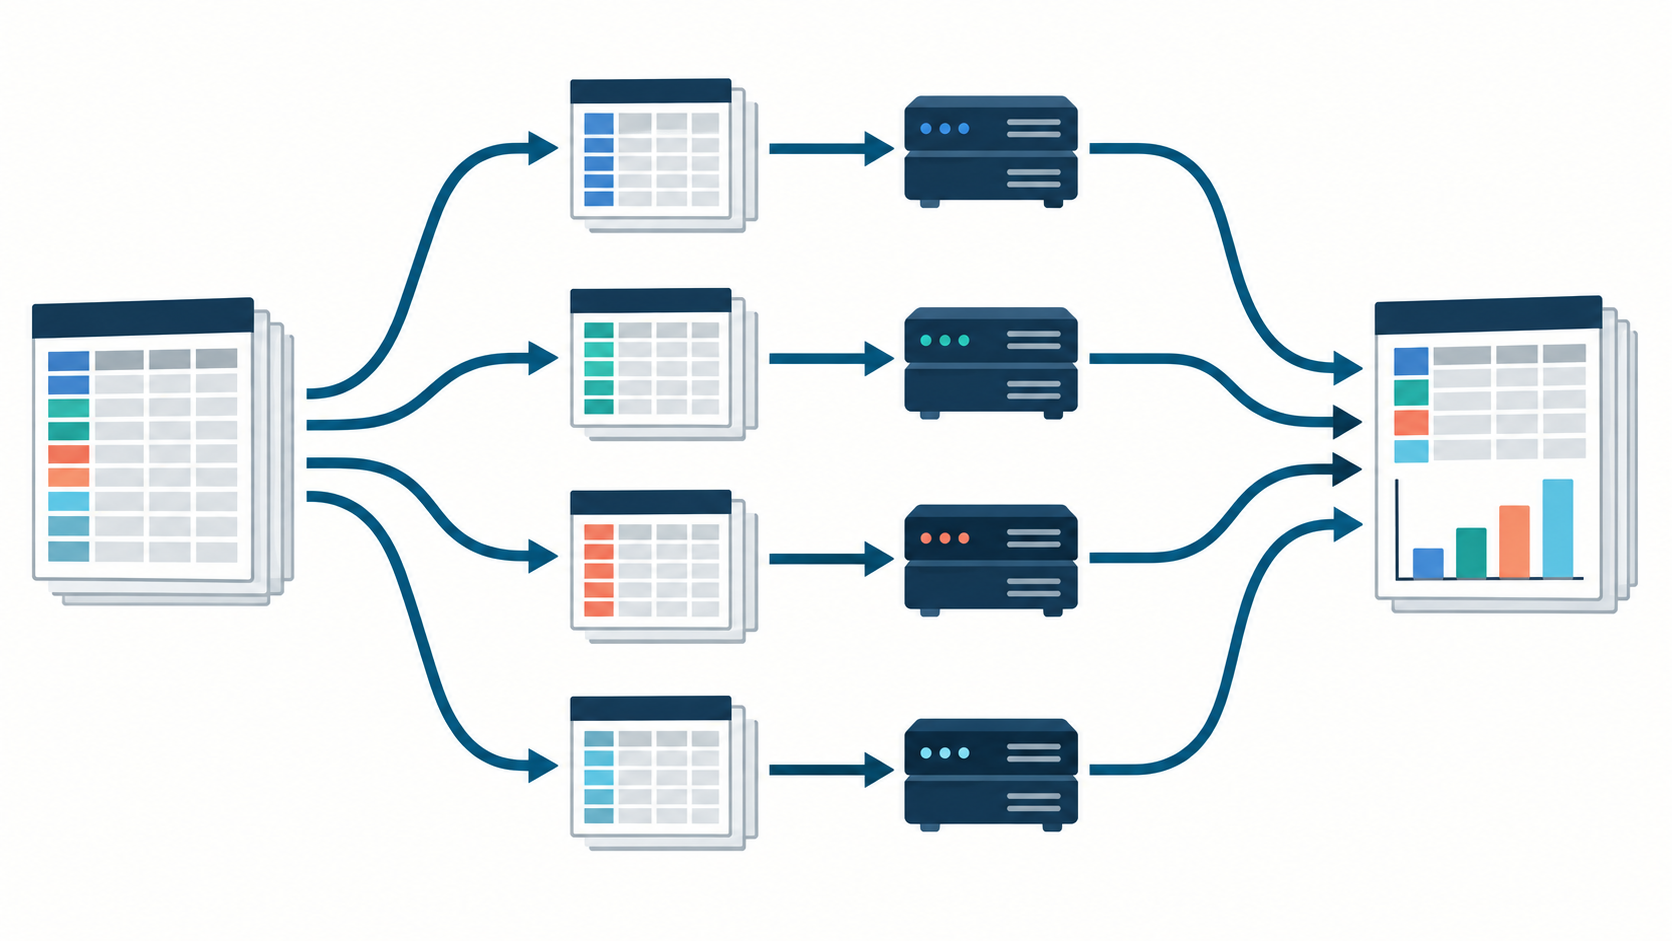

*Podział pracy i połączenie wyników na jednej maszynie. Ilustracja koncepcyjna.*

### Jak dodatkowe wątki wpływają na czas operacji overlap?
Dla porównania – **opublikowany wynik z dokumentacji polars-bio** dla tego samego zestawu ex-rna × ex-anno (inna maszyna, starsza wersja biblioteki). Porównaj go ze swoim wykresem.

**Zadanie:** wyszukiwanie przecięć dwóch dużych zbiorów przedziałów AIList, **ex-rna × ex-anno (para 8-7)**. Mają około 9,945 mln i 1,194 mln przedziałów; artykuł podaje około **307 mln par przecięć**. Są to inne dane niż HG002 i GENCODE z C2.

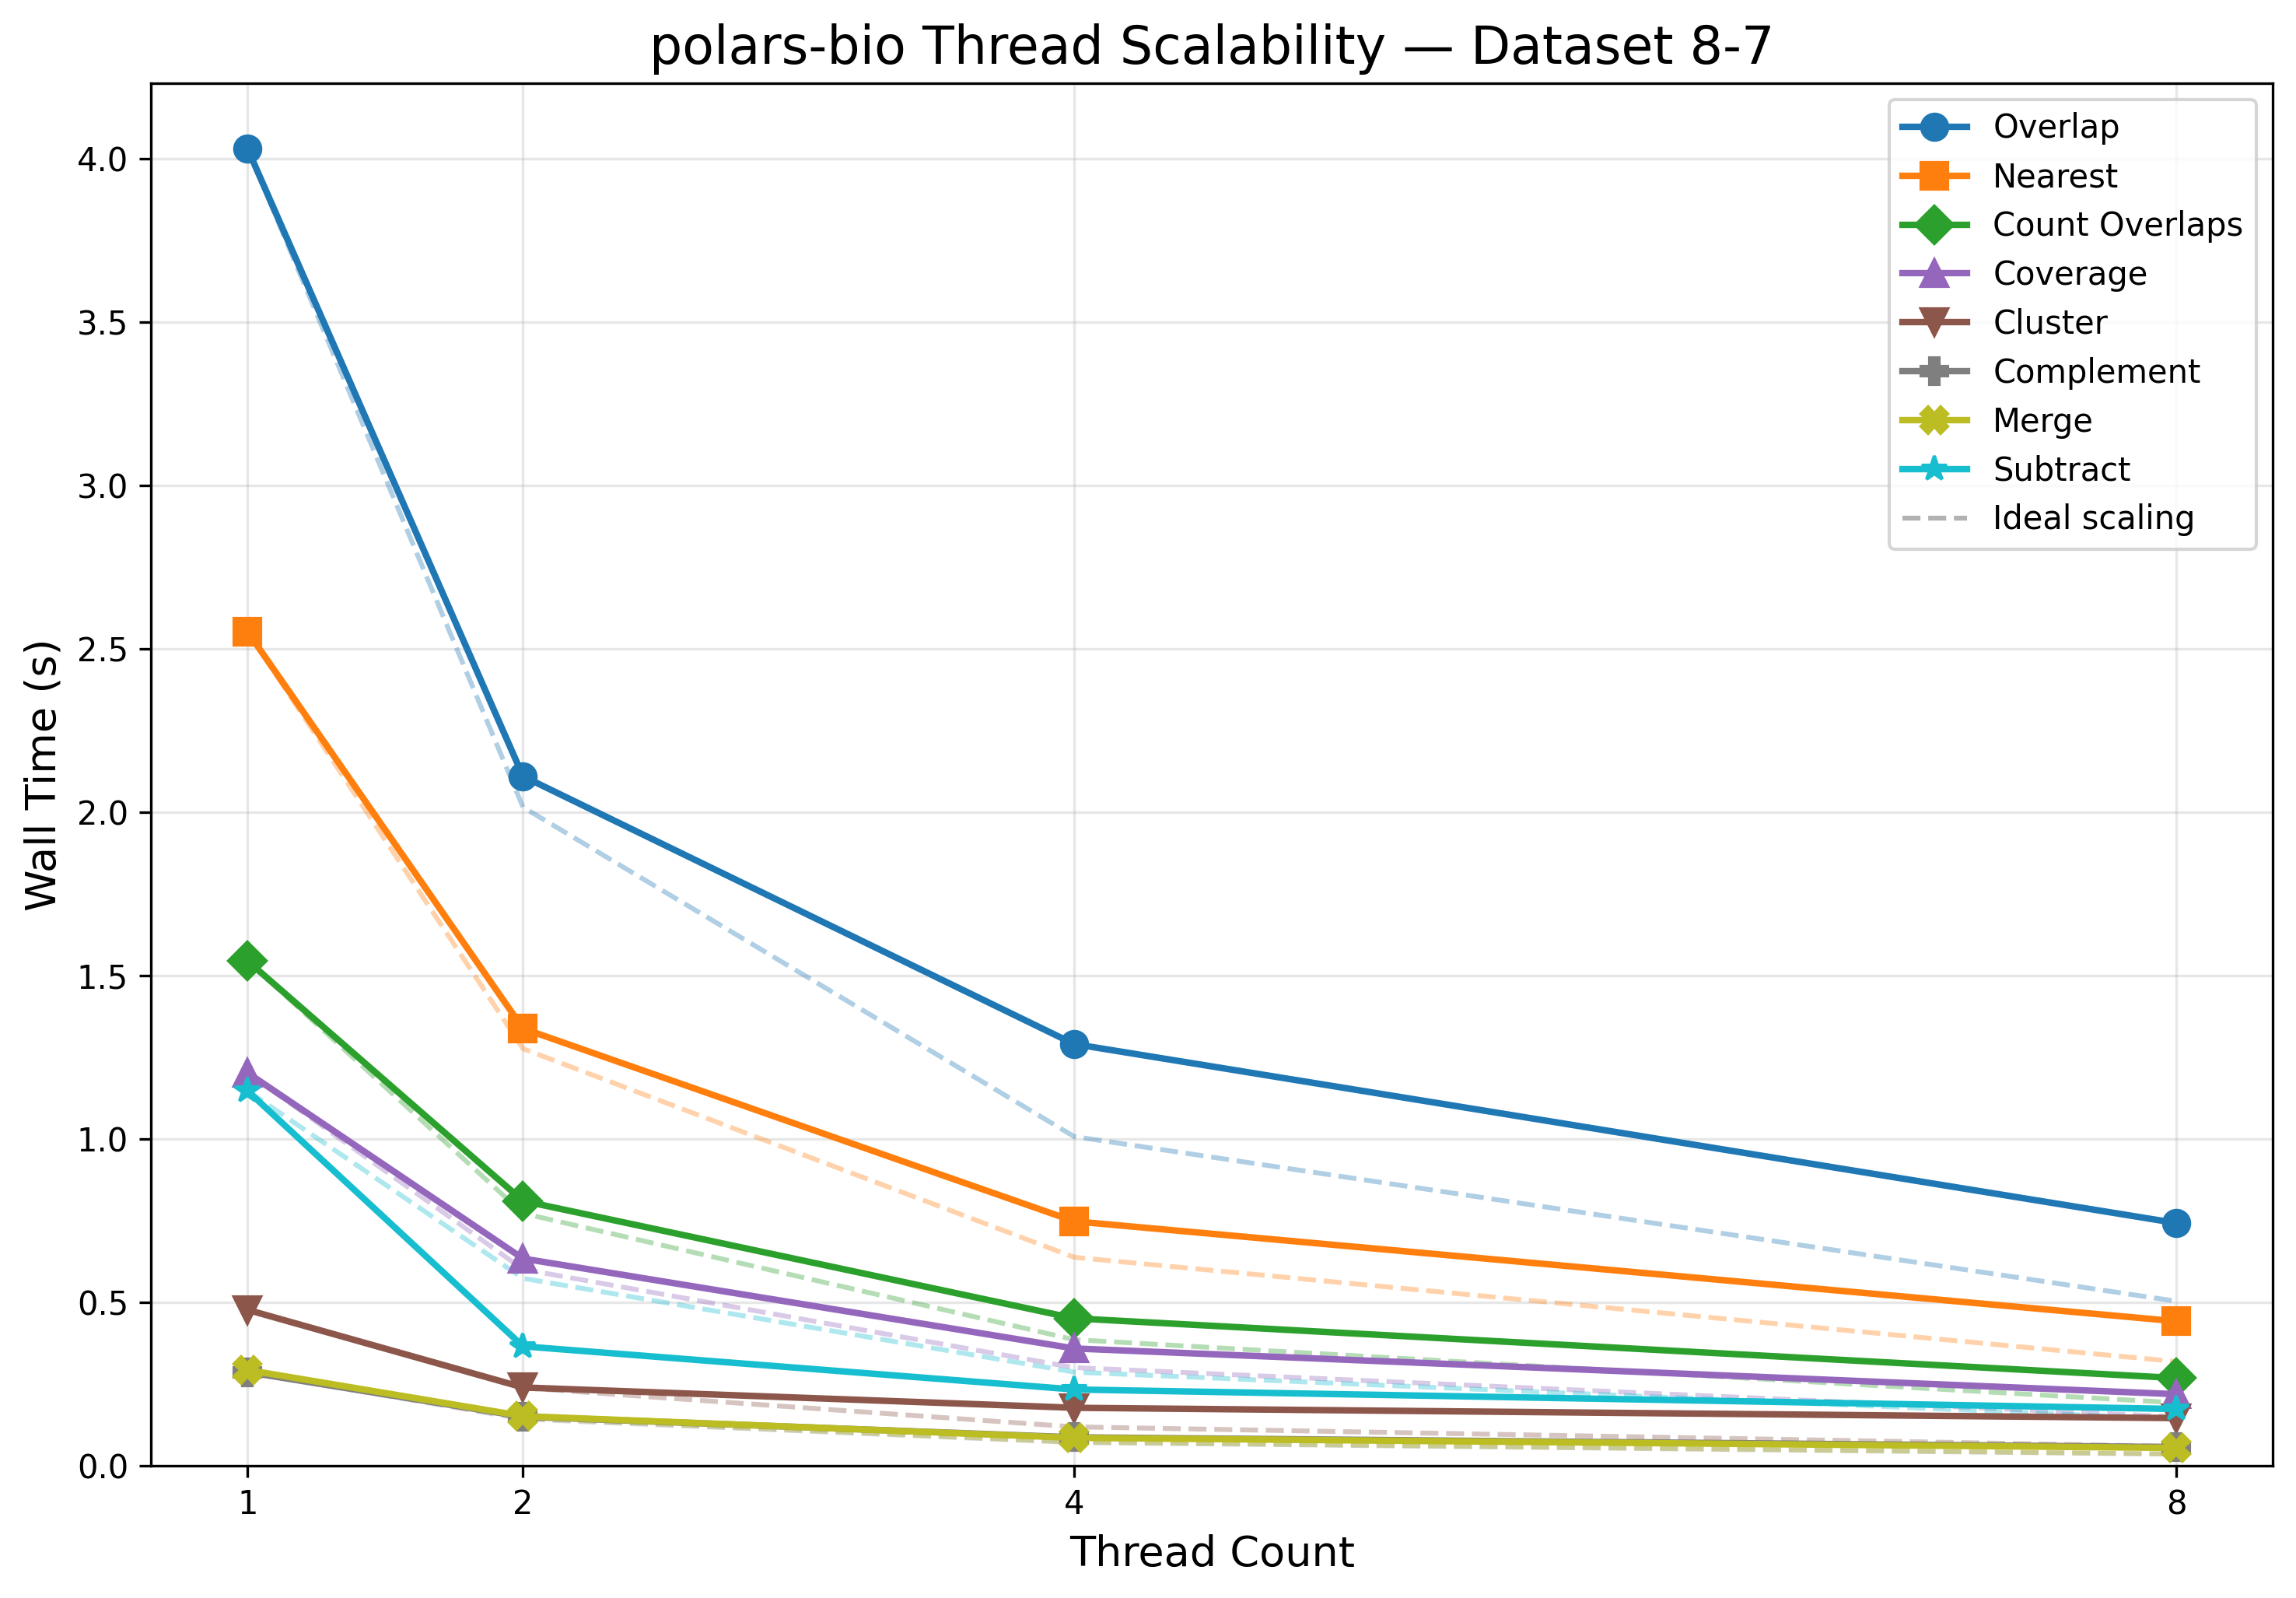

**Patrzymy na niebieską linię „Overlap”.** Oś pozioma oznacza liczbę wątków, pionowa — czas w sekundach (niżej = szybciej). Pozostałe kolory dotyczą innych operacji przedziałowych. Linie przerywane pokazują idealny spadek czasu proporcjonalny do liczby wątków.

| Operacja | 1 wątek | 8 wątków | Przyspieszenie podane w źródle |
|---|---:|---:|---:|
| Overlap | 4,03 s | 0,74 s | 5,43× |

**Przyspieszenie = czas przy 1 wątku / czas przy N wątkach.** Osiem wątków nie oznacza automatycznie ośmiokrotnie krótszego czasu: część pracy wykonuje się kolejno, a podział zadań i dostęp do pamięci mają swój koszt.

**Do omówienia:** dlaczego niebieska linia przy 8 wątkach jest powyżej przerywanej linii idealnego skalowania?

*Źródło: [Interval operations benchmark — update February 2026](https://biodatageeks.org/polars-bio/blog/2026/02/20/interval-operations-benchmark--update-february-2026/#thread-scalability-dataset-8-7), 20.02.2026. Pomiar dotyczy polars-bio **0.24.0**; w ćwiczeniu używamy **0.36.0**. Artykuł nie podaje konfiguracji sprzętu dla tego wykresu. To wynik opublikowanego eksperymentu, a nie pomiar na Twoim laptopie. Czasy w tabeli są zaokrąglone.*

## C4 · Streaming: duży wynik zapisujemy porcjami
**Streaming, czyli przetwarzanie strumieniowe**, polega na czytaniu i przetwarzaniu kolejnych porcji danych. Wynik może od razu trafiać do pliku. Dzięki temu nie trzeba gromadzić całej tabeli wynikowej w RAM.

| Pojęcie | Co oznacza w naszym ćwiczeniu? |
|---|---|
| Leniwe zapytanie | Najpierw opisujemy operacje; wykonanie uruchamia `collect()` lub `sink_parquet()` |
| Streaming | Podczas wykonania dane przepływają porcjami |
| Równoległość | Części pracy mogą wykonywać się jednocześnie |

Te mechanizmy można łączyć. Samo przygotowanie leniwego zapytania nie gwarantuje małego zużycia pamięci.

`collect(engine="streaming")` może przetwarzać wejście porcjami, ale **końcowy DataFrame nadal musi zmieścić się w RAM**. `sink_parquet()` zapisuje wynik w trakcie obliczeń. Czytnik, bufory i kompresja nadal potrzebują pamięci; streaming nie oznacza zerowego zużycia RAM.

### Dlaczego zapisujemy Parquet?
**Parquet** to binarny format tabel, który zapisuje wartości kolumnami i obsługuje kompresję. Jeśli później potrzebujemy tylko `chrom` i `start`, czytnik może odczytać te kolumny bez wczytywania pozostałych. Plik dzieli się na grupy wierszy (*row groups*); zapisane statystyki mogą pomagać pomijać niepotrzebne grupy.

W kodzie `compression='zstd'` wybiera sposób kompresji, a `row_group_size=5000` ustawia wielkość grup wierszy w pliku. Ten parametr sam w sobie nie jest limitem RAM. VCF pozostaje plikiem wejściowym, a Parquet służy nam do dalszej analizy tabeli. [Apache Parquet](https://parquet.apache.org/docs/overview/) · [Polars: streaming](https://docs.pola.rs/user-guide/concepts/streaming/).

### Osobne doświadczenie z pamięcią: zapis wszystkich SNV
Tabela przecięć z C2 jest stosunkowo mała. Żeby porównać pamięć potrzebną na **duży wynik**, teraz zapisujemy wszystkie **3 458 690 SNV** z pełnego VCF: chr1–22, długość REF i ALT równa 1. Funkcja `vcf_query` wybiera sześć kolumn: `chrom`, `start`, `ref`, `alt`, `qual`, `filter`. Zachowuje pozycję VCF **od 1**; nie stosuje progu jakości ani warunku PASS.

To inne zapytanie niż `overlap` w C2. W obu wariantach C4 obejmujemy czasem odczyt VCF, dekompresję, wybór SNV i zapis Parquet. Różnicą jest sposób gromadzenia wyniku przed zapisem.

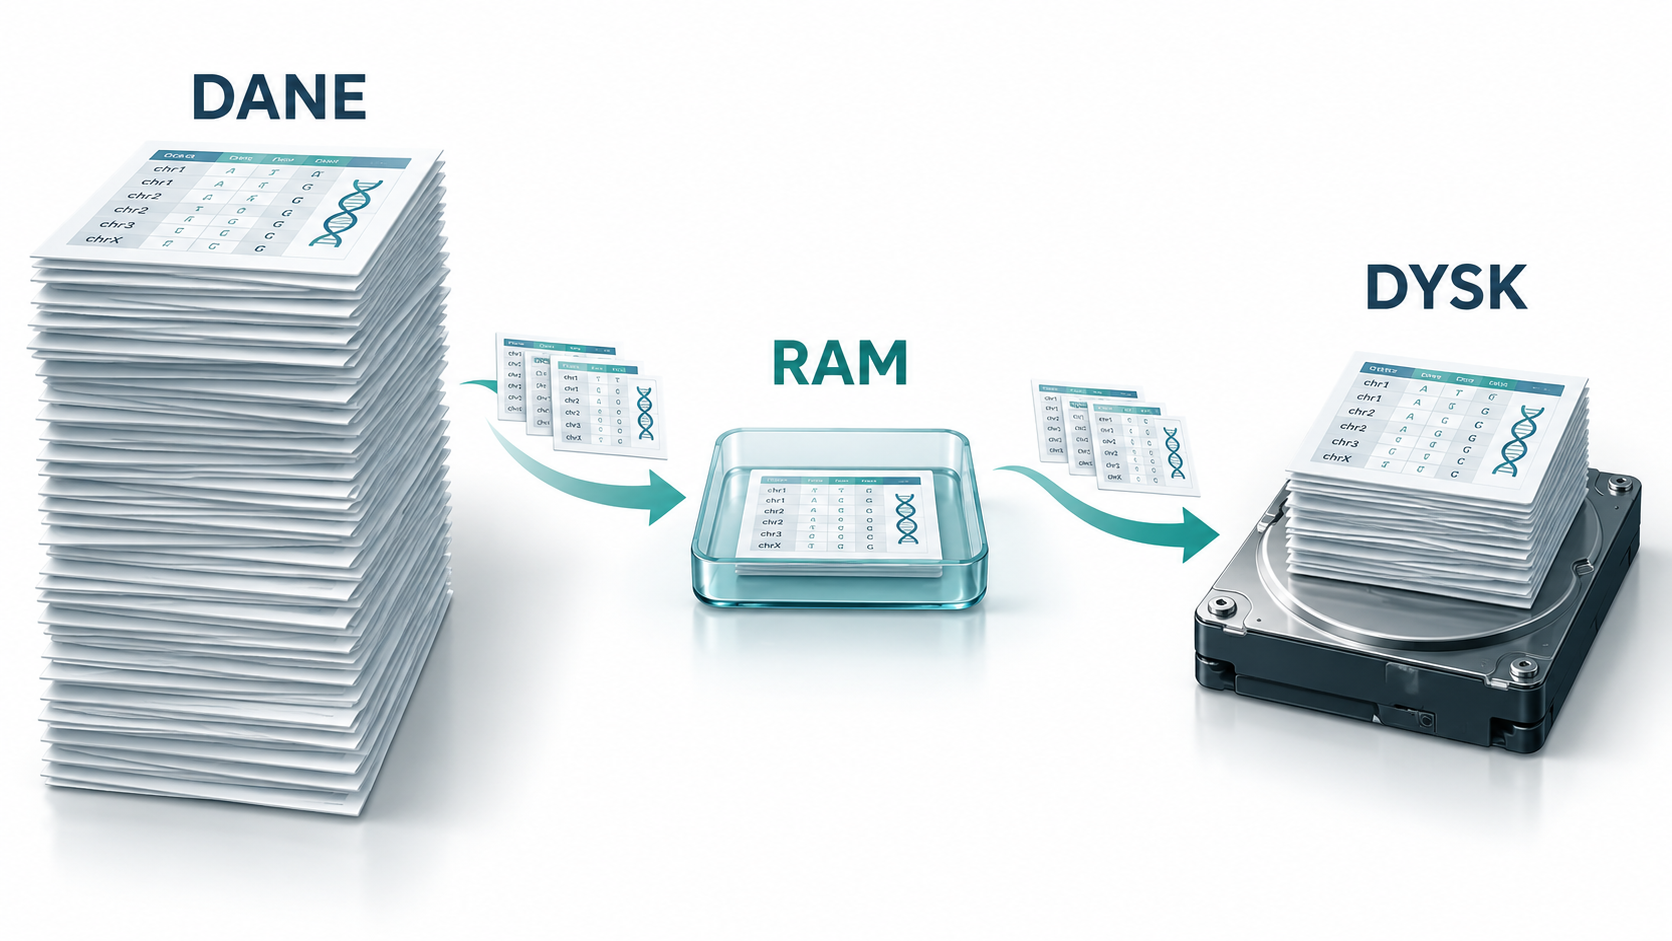

*W pamięci znajduje się porcja danych, a wynik przyrasta na dysku. Ilustracja koncepcyjna.*

In [ ]:
pb.set_option('datafusion.execution.target_partitions', '1')
filtered_path = OUT / 'snv.parquet'
vcf_query(str(vcf)).sink_parquet(
    filtered_path, compression='zstd', row_group_size=5000
)
print('Wynik:', filtered_path)
display(pl.scan_parquet(filtered_path).select('chrom','start','ref','alt').head(5).collect())

Porównamy **dwie drogi do tego samego pliku**: zebranie całej tabeli w RAM i zapis oraz bezpośredni zapis porcjami. W obu przypadkach ten sam filtr, kompresja i wielkość grupy wierszy. Równoległość pozostaje ustawiona na 1.

Sprawdzamy czas i **maksymalne zaobserwowane RSS**, czyli największą ilość fizycznej pamięci RAM zajmowanej przez proces w zebranych próbkach. Osobny monitor odczytuje bieżące RSS **co około 10 ms podczas wykonania zapytania i zapisu**. Pomiar obejmuje pamięć bibliotek i buforów obecnych w tym czasie; kończy się przed wczytaniem wyniku do sprawdzenia zgodności. Nie obejmuje wcześniejszego przygotowania danych w notebooku. Bardzo krótkie skoki pamięci mogą wypaść między próbkami.

Streaming nie musi być szybszy — jego głównym celem jest ograniczenie pamięci potrzebnej na wynik. Jeśli odczyt i bufory dominują nad rozmiarem końcowej tabeli, różnica RSS także może być niewielka.

In [ ]:
streaming = wh.measure_streaming(vcf)

### Jak odczytać oba wykresy?

| Miara | Pytanie do wyniku |
|---|---|
| Czas | Jak długo czekamy na ten sam wynik? |
| Maksymalne zaobserwowane RSS | Ile pamięci zajmował proces podczas analizy i zapisu? |
| Zgodność | Czy liczba rekordów i sumy kontrolne wartości się zgadzają? |

Mniejsze RSS może towarzyszyć podobnemu czasowi. Z kolei większa równoległość może wymagać więcej pamięci na bufory. **Do omówienia:** który wariant wybierzesz, jeśli tabela wynikowa będzie większa od dostępnego RAM?

## C5 · Adnotacja: vepyr jako szybka alternatywa dla VEP
**Adnotacja wariantu** polega na dodaniu kontekstu biologicznego do pozycji i zmiany sekwencji: genu, transkryptu, przewidywanej konsekwencji albo informacji z bazy znanych wariantów.

**Ensembl VEP (Variant Effect Predictor)** jest narzędziem do takiej adnotacji. **vepyr** to nowa implementacja tej klasy analizy w języku Rust, dostępna z Pythona. Korzysta z lokalnych baz pochodzących z Ensembl VEP i zwraca m.in. tabelę Polars, którą można dalej filtrować i zapisywać. [Ensembl VEP](https://www.ensembl.org/info/docs/tools/vep/index.html) · [Projekt vepyr](https://github.com/biodatageeks/vepyr).

### Ile może trwać adnotacja całego genomu?
Poniżej **zapisane porównanie VEP i vepyra na Linuksie**. To punkt wyjścia do pokazania vepyra jako szybkiej alternatywy.

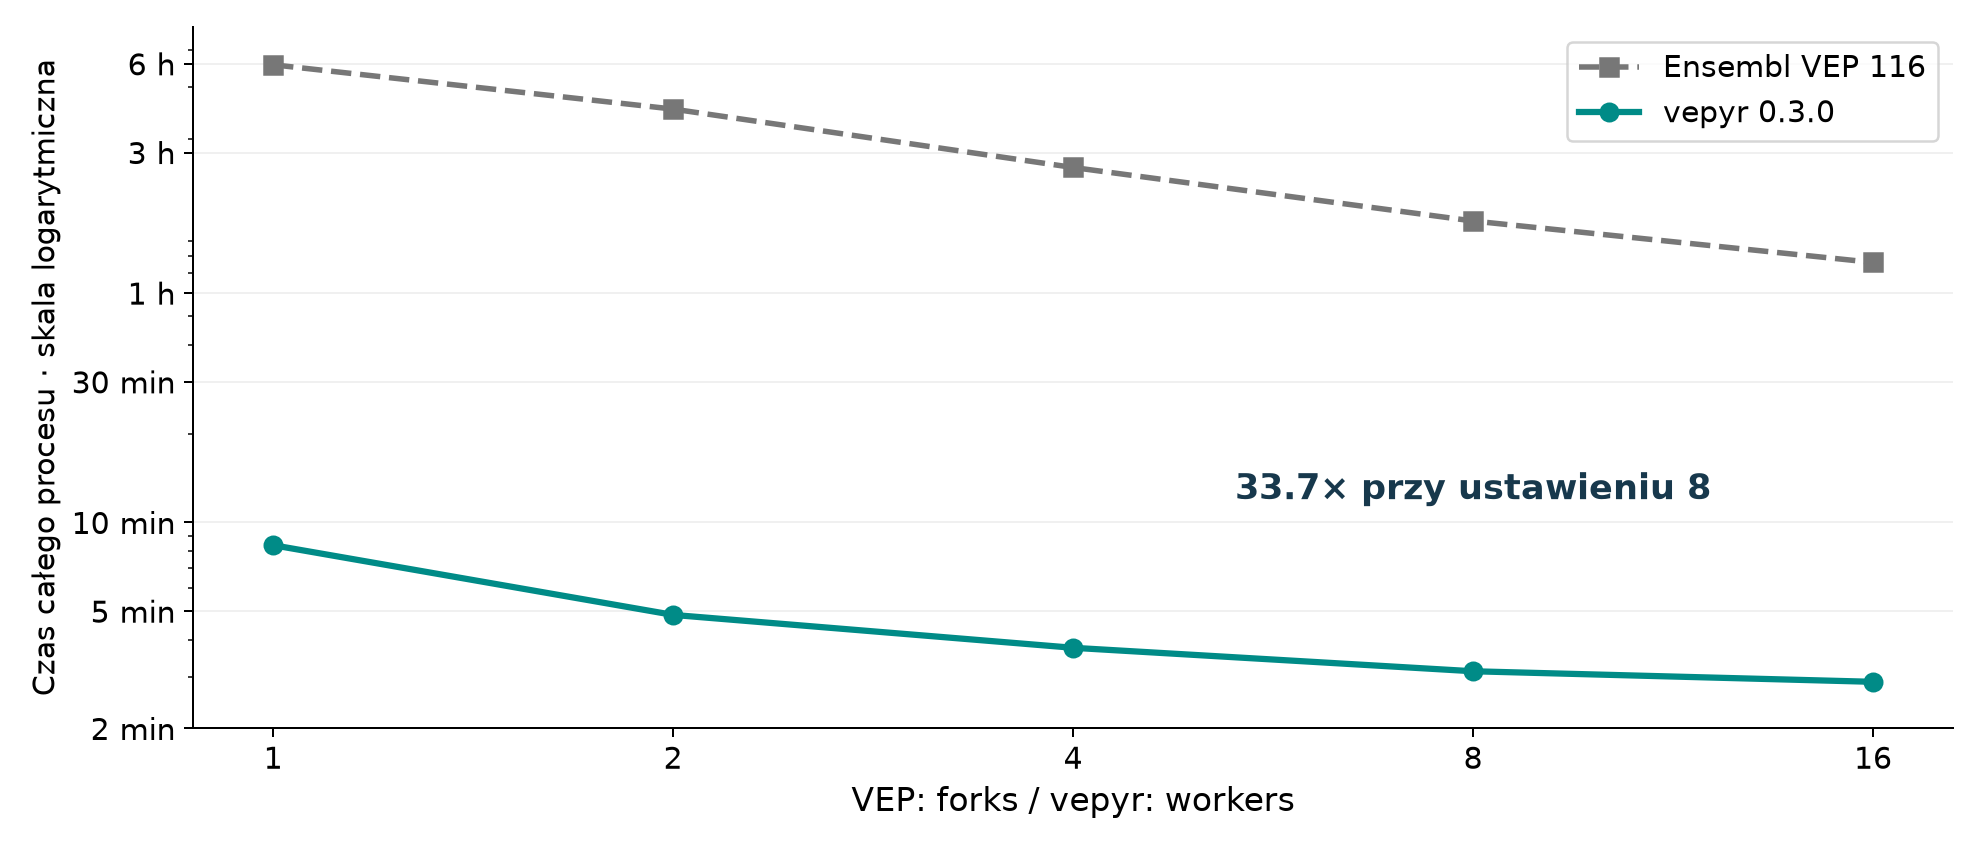

**Jak czytać wykres:** oś pozioma pokazuje ustawienia równoległości (`forks` w VEP, `workers` w vepyrze), a oś pionowa czas całego procesu. Oś czasu jest **logarytmiczna**: równe odstępy oznaczają pomnożenie czasu przez tę samą wartość, np. przejście od 2 do 4 minut i od 4 do 8 minut. Niższa wartość oznacza krótszy czas.

| Warunki zapisanego porównania | Wartość |
|---|---|
| Dane | HG002, chr1–22, 4 096 123 warianty, GRCh38 |
| Narzędzia | Ensembl VEP 116 i vepyr 0.3.0 |
| Baza i zakres | Merged cache 116 (Ensembl + RefSeq), pełna adnotacja z HGVS — standardowym opisem zmiany sekwencji |
| Środowisko i wynik | Linux/x86-64, nieskompresowany VCF zapisany na SSD; czas całego procesu |
| Ustawienie 8 | VEP: 1 godz. 45 min 26 s; vepyr: 3 min 08 s — około **33,7× krócej** |

Są to pojedyncze uruchomienia na innej maszynie; wynik nie przewiduje czasu na Twoim laptopie. Liczba workerów nie jest ścisłym limitem wszystkich wątków programu. Szybkość i zgodność biologicznych adnotacji oceniamy osobno: ten wykres przedstawia czas.

Źródło: dostarczone tabele pomiarów `vep/outputs/116/merged_fork_scaling/summary.tsv` i `vepyr/outputs/116/merged_worker_scaling/summary.tsv` z [performance-tests projektu vepyr](https://github.com/biodatageeks/vepyr/tree/master/performance-tests).

### Nasze ćwiczenie: adnotacja chr22 i interpretacja wyniku
Dla **50 284 rekordów chr22** dodajemy geny, transkrypty, konsekwencje i częstość z bazy adnotacyjnej. Używamy **vepyr 0.9.0, cache Ensembl 116 / GRCh38 i FASTA chr22**. **0.9.0 to wersja programu; 116 to wydanie danych Ensembl/VEP.**

| Informacja w VCF | Kontekst dodany przez adnotację |
|---|---|
| Chromosom i pozycja | Gen oraz transkrypt obejmujący tę pozycję |
| REF i ALT | Przewidywana konsekwencja zmiany |
| Identyfikacja wariantu | Dostępne informacje z baz, np. częstość allelu |

**Transkrypt** to zapis konkretnej wersji RNA powstającej z genu; jeden gen może mieć wiele transkryptów. Ten sam wariant może mieć różne konsekwencje zależnie od transkryptu. Wynik adnotacji zależy od genomu odniesienia, zestawu transkryptów i wersji bazy. Cache to lokalna, wersjonowana baza: podczas adnotacji nie wysyłamy wariantów do zewnętrznego API.

Parametr `workers` ustala, ilu równoległych wykonawców dzieli między siebie warianty. Najpierw adnotujemy jednym workerem, potem porównamy czas z większą liczbą workerów – tak jak executory Sparka w części 1, tylko na jednej maszynie.

In [ ]:
import os
import vepyr

def annotate(workers):
    return vepyr.annotate(
        str(annotation_vcf), str(cache), workers=workers,
        reference_fasta=str(reference_fasta),
        expected_cache_version='116', show_progress=False,
    ).select(
        'chrom', 'start', 'ref', 'alt', 'SYMBOL', 'Feature',
        'Consequence', 'most_severe_consequence', 'IMPACT', 'AF'
    )

annotation_path = OUT / 'adnotacje_chr22.parquet'
_, annotation_seconds = ws.timed('vepyr, 1 worker',
                                 lambda: annotate(1).sink_parquet(annotation_path, row_group_size=5000))
annotated = pl.scan_parquet(annotation_path)
display(annotated.select('chrom','start','SYMBOL','most_severe_consequence','AF').head(8).collect())

Ta sama adnotacja z większą liczbą workerów. Wynik zapisujemy do osobnego pliku i sprawdzamy, czy liczba rekordów jest taka sama.

In [ ]:
workers = min(4, os.cpu_count())
parallel_path = OUT / f'adnotacje_chr22_{workers}w.parquet'
_, parallel_seconds = ws.timed(f'vepyr, {workers} workery',
                               lambda: annotate(workers).sink_parquet(parallel_path, row_group_size=5000))
n1 = annotated.select(pl.len()).collect().item()
n2 = pl.scan_parquet(parallel_path).select(pl.len()).collect().item()
print(f'Rekordy: {n1} i {n2}; przyspieszenie {annotation_seconds / parallel_seconds:.1f}× przy {workers} workerach')

50 tysięcy wariantów to dla vepyra kilka sekund pracy, więc zysk z kolejnych workerów jest umiarkowany – rośnie z rozmiarem danych (por. wykres dla całego genomu, 4 mln wariantów, powyżej). **Do omówienia:** ile trwałaby adnotacja chr22 programem VEP na klastrze Sparka z części 1?

| Pole | Jak je czytać |
|---|---|
| SYMBOL / Feature | Gen / transkrypt; listy mogą zawierać wiele elementów |
| Consequence | Konsekwencje odpowiadające poszczególnym wpisom adnotacji |
| most_severe_consequence | Jedna kategoria według hierarchii konsekwencji |
| IMPACT | Przewidywany wpływ molekularny, nie klasyfikacja patogenności |
| AF | Częstość z dostępnej bazy; brak wartości nie oznacza zera |

Jeden wariant może dotyczyć wielu transkryptów. Nie rozdzielamy niezależnie list genów i konsekwencji: trzeba zachować ich powiązania.

In [ ]:
wh.annotation_chart(annotated.select('most_severe_consequence').collect())
consequence = 'missense_variant'  # spróbuj także 'intron_variant'
max_af = 0.01
selected = annotated.filter(
    (pl.col('most_severe_consequence') == consequence) &
    pl.col('AF').is_not_null() & (pl.col('AF') < max_af)
)
display(selected.select('chrom','start','ref','alt','SYMBOL','AF').head(10).collect())
print('Rekordy spełniające kryteria:', selected.select(pl.len()).collect().item())
print('Rekordy bez AF:', annotated.filter(pl.col('AF').is_null()).select(pl.len()).collect().item())

**Ćwiczenie:** zmień konsekwencję albo próg AF i przewidź kierunek zmiany liczby rekordów. Czy wariant bez AF powinien automatycznie przejść jako rzadki? Dlaczego?

Selekcja pomaga zawęzić zbiór. Rzadkość i przewidywana konsekwencja same nie rozstrzygają o patogenności. W tym przykładzie rekordy bez AF liczymy oddzielnie.

## C6 · Dane w kubełkach i wynik z części 2

polars-bio czyta formaty genomowe **wprost z obiektowej pamięci masowej** (`gs://`, `s3://`), strumieniowo i fragmentami – bez kopiowania całego pliku na dysk (część 1, sekcja o kubełkach). Poniżej odczytujemy tylko **nagłówek** pliku VCF z publicznego kubełka gnomAD – kilkadziesiąt kilobajtów z pliku liczącego gigabajty. Komórka wymaga połączenia z internetem.

In [ ]:
remote_vcf = 'gs://gcp-public-data--gnomad/release/4.1/genome_sv/gnomad.v4.1.sv.sites.vcf.gz'
header = pb.describe_vcf(remote_vcf, allow_anonymous=True)
header

Na koniec wróćmy do części 2. Potok `hc-sharded.wdl` zapisał scalony plik VCF trio w katalogu `cromwell-executions`. Policzmy w nim warianty i typy zmian tym samym narzędziem, którym analizowaliśmy HG002 (jeśli potok nie był uruchomiony, komórka to zgłosi).

In [ ]:
from glob import glob

runs = sorted(glob('cromwell-executions/sharded_variant_calling/*/call-MergeVcfs/execution/merged.vcf'))
if not runs:
    print('Brak wyniku potoku z części 2 – uruchom dags/hc-sharded.wdl w notatniku 02.')
else:
    trio_vcf = runs[-1]
    print('Plik:', trio_vcf)
    calls = pb.scan_vcf(trio_vcf, info_fields=[], format_fields=[])
    display(calls.select(
        pl.len().alias('warianty'),
        ((pl.col('ref').str.len_chars() == 1) & (pl.col('alt').str.len_chars() == 1)).sum().alias('SNV'),
    ).collect())

## Podsumowanie dnia: trzy sposoby dzielenia pracy

| | Apache Spark (cz. 1) | WDL + Cromwell (cz. 2) | polars-bio, vepyr (cz. 3) |
|---|---|---|---|
| Jednostka pracy | partycja danych → zadanie w executorze | shard → osobne zadanie (proces, kontener) | partycja / porcja danych → wątek w jednym procesie |
| Kto dzieli dane | silnik (format, rozmiar plików) | autor potoku (`scatter`, interwały) | silnik (`target_partitions`, `workers`) |
| Leniwość | plan do pierwszej akcji (`explain`) | graf zależności zadań | `LazyFrame` do `collect` / `sink_parquet` |
| Narzut | JVM, shuffle przez sieć | start programu i kopiowanie plików w każdym shardzie | wspólna pamięć, brak kopiowania |
| Kiedy | dane > jedna maszyna, wielu użytkowników klastra | potoki z wieloma narzędziami (bwa, GATK), produkcja | analizy ad hoc, eksploracja, adnotacja na laptopie lub jednej dużej maszynie |

### Jak zachować i odtworzyć wynik?

| Co zachować | Co zapisujemy w tym ćwiczeniu |
|---|---|
| Środowisko | Tag obrazu Dockera (`tgambin65716/omics-bigdata:2026.10`) – wszystkie wersje narzędzi są w `/opt/workshop/VERSIONS.txt` |
| Wejście | Źródło HG002, GRCh38, wersję danych i sumę kontrolną pliku (`part3/data/real_sources.json`) |
| Analiza | Wersje narzędzi, Ensembl 116 i parametry zapytań |
| Wynik | `wyniki/snv.parquet`, `wyniki/adnotacje_chr22.parquet` oraz metadane pomiarów |

**Suma kontrolna** to skrót obliczony z zawartości pliku, pozwalający sprawdzić, czy otrzymaliśmy te same bajty. Pomaga identyfikować wejście; nie zastępuje oceny poprawności biologicznej.

## Dane referencyjne i źródła
Jeżeli nie uda się wykonać adnotacji, po instalacji bibliotek można obejrzeć zapisaną tabelę dla tych samych publicznych danych. Jest to **wynik referencyjny**, a nie wynik bieżącej sesji.

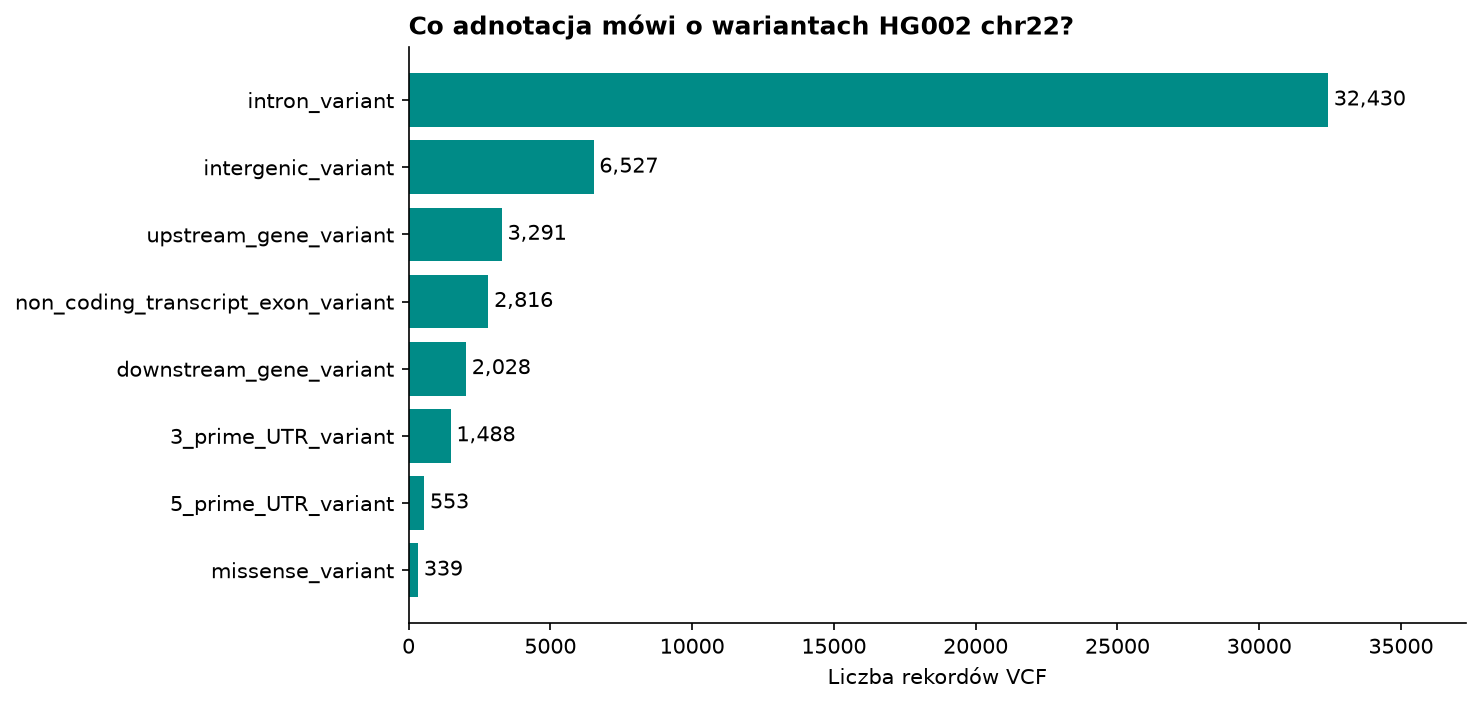

*Zapisana adnotacja HG002 chr22: 50 284 rekordy, Ensembl 116. Wykres bieżącej sesji powstaje w C5.*

In [ ]:
reference = pl.read_parquet(ROOT / 'reference/real/serial/annotations.parquet')
reference.select('chrom','start','SYMBOL','most_severe_consequence').head(5)

- [GIAB HG002, GRCh38, v4.2.1](https://ftp-trace.ncbi.nlm.nih.gov/ReferenceSamples/giab/release/AshkenazimTrio/HG002_NA24385_son/NISTv4.2.1/GRCh38/)
- [GENCODE 47 / GRCh38: mapa genów i eksonów](https://www.gencodegenes.org/human/release_47.html)
- [FASTA chr22: UCSC hg38 / GRCh38](https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/)
- [polars-bio: operacje przedziałowe](https://biodatageeks.org/polars-bio/api/operations/) · [Polars: leniwe zapytania](https://docs.pola.rs/user-guide/concepts/lazy-api/) · [streaming](https://docs.pola.rs/user-guide/concepts/streaming/)
- [Apache Parquet](https://parquet.apache.org/docs/overview/)
- [Ensembl VEP](https://www.ensembl.org/info/docs/tools/vep/index.html) · [vepyr](https://github.com/biodatageeks/vepyr) · [cache Ensembl 116](https://huggingface.co/datasets/biodatageeks/vepyr_116_GRCh38_ensembl)
- [NHGRI: prywatność danych genomowych](https://www.genome.gov/about-genomics/policy-issues/Privacy)

Dokładne adresy i sumy kontrolne pobieranych danych znajdują się w `/opt/workshop/part3/data/real_sources.json`. Ilustracje koncepcyjne wygenerowano na potrzeby warsztatu; schemat współrzędnych narysowano w Matplotlib. Wykres skalowania w C3 pochodzi z dokumentacji polars-bio. Wykresy czasu i pamięci w C3 i C4 powstają z wykonania kodu w bieżącej sesji. Porównanie VEP–vepyr w C5 i powyższy rozkład konsekwencji są zapisanymi wynikami referencyjnymi.